<a href="https://colab.research.google.com/github/XinWEI2000/SoftBeamResonance/blob/main/Deepmind_TAPIR_beam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# @title Install Code and Dependencies {form-width: "25%"}
!pip install 'tapnet[torch] @ git+https://github.com/google-deepmind/tapnet.git'

  Cloning https://github.com/google-deepmind/tapnet.git to /tmp/pip-install-i2_b_057/tapnet_cf2cbd65c0f24518b79f39c2df8eb2b7
  Running command git clone --filter=blob:none --quiet https://github.com/google-deepmind/tapnet.git /tmp/pip-install-i2_b_057/tapnet_cf2cbd65c0f24518b79f39c2df8eb2b7
  Resolved https://github.com/google-deepmind/tapnet.git to commit ceedd60bb9f6c9f7c74796e4445aff6c6ddf7c9b
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
## -------- checking the availability of GPU------------
import torch

print("GPU 是否可用：", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU 型号：", torch.cuda.get_device_name(0))

GPU 是否可用： True
GPU 型号： Tesla T4


In [ ]:
# @title Download Model {form-width: "25%"}

%mkdir tapnet/checkpoints

!wget -P tapnet/checkpoints https://storage.googleapis.com/dm-tapnet/bootstap/bootstapir_checkpoint_v2.pt

%ls tapnet/checkpoints

mkdir: cannot create directory ‘tapnet/checkpoints’: No such file or directory
--2026-11-10 23:25:11--  https://storage.googleapis.com/dm-tapnet/bootstap/bootstapir_checkpoint_v2.pt
Resolving storage.googleapis.com (storage.googleapis.com)... 142.251.18.207, 172.253.153.207, 142.250.145.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.251.18.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 218886140 (209M) [application/octet-stream]
Saving to: ‘tapnet/checkpoints/bootstapir_checkpoint_v2.pt’

bootstapir_checkpoi 100%[===================>] 208.75M  41.6MB/s    in 5.9s    

2026-11-10 23:25:18 (35.1 MB/s) - ‘tapnet/checkpoints/bootstapir_checkpoint_v2.pt’ saved [218886140/218886140]

bootstapir_checkpoint_v2.pt


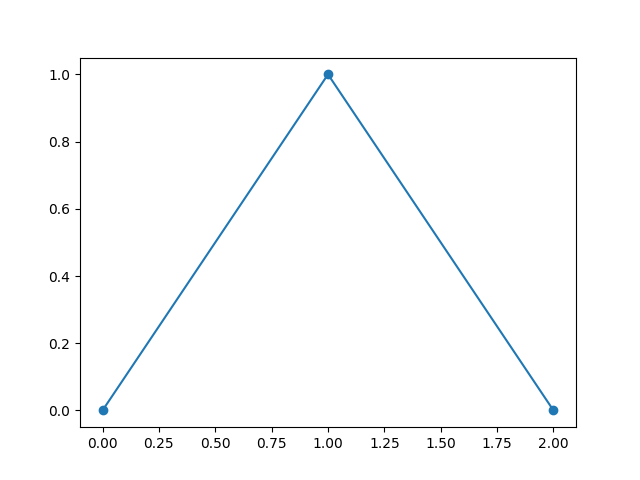

In [ ]:
## ---------------------Pre-import------------------------/

from matplotlib.backends import backend_registry

# 补齐已安装的 ipympl 后端注册信息
known_backends = set(backend_registry.list_all())
missing_entries = [
    (name, "ipympl.backend_nbagg")
    for name in ("ipympl", "widget")
    if name not in known_backends
]
if missing_entries:
    backend_registry._validate_and_store_entry_points(missing_entries)

from google.colab import output
output.enable_custom_widget_manager()

%matplotlib widget
import matplotlib.pyplot as plt

# 测试交互绘图
fig, ax = plt.subplots()
ax.plot([0, 1, 2], [0, 1, 0], "o-")
plt.show()

In [ ]:
# @title Imports {form-width: "25%"}
%matplotlib widget
from google.colab import output
import jax
import matplotlib.pyplot as plt
import mediapy as media
import numpy as np
from tapnet.torch import tapir_model
from tapnet.utils import transforms
from tapnet.utils import viz_utils
import torch
import torch.nn.functional as F

output.enable_custom_widget_manager()

In [ ]:
# @title Select Device {form-width: "25%"}

if torch.cuda.is_available():
  device = torch.device('cuda')
else:
  device = torch.device('cpu')

In [ ]:
# @title Utility Functions {form-width: "25%"}


def preprocess_frames(frames):
  """Preprocess frames to model inputs.

  Args:
    frames: [num_frames, height, width, 3], [0, 255], np.uint8

  Returns:
    frames: [num_frames, height, width, 3], [-1, 1], np.float32
  """
  frames = frames.float()
  frames = frames / 255 * 2 - 1
  return frames


def sample_random_points(frame_max_idx, height, width, num_points):
  """Sample random points with (time, height, width) order."""
  y = np.random.randint(0, height, (num_points, 1))
  x = np.random.randint(0, width, (num_points, 1))
  t = np.random.randint(0, frame_max_idx + 1, (num_points, 1))
  points = np.concatenate((t, y, x), axis=-1).astype(
      np.int32
  )  # [num_points, 3]
  return points


def postprocess_occlusions(occlusions, expected_dist):
  visibles = (1 - F.sigmoid(occlusions)) * (1 - F.sigmoid(expected_dist)) > 0.5
  return visibles


def inference(frames, query_points, model):
  # Preprocess video to match model inputs format
  frames = preprocess_frames(frames)
  query_points = query_points.float()
  frames, query_points = frames[None], query_points[None]

  # Model inference
  outputs = model(frames, query_points)
  tracks, occlusions, expected_dist = (
      outputs['tracks'][0],
      outputs['occlusion'][0],
      outputs['expected_dist'][0],
  )

  # Binarize occlusions
  visibles = postprocess_occlusions(occlusions, expected_dist)
  return tracks, visibles

In [ ]:
## ----------Select my own video ---------------------------

from google.colab import files
import mediapy as media

uploaded = files.upload()  # 选择一个自己的视频，建议先用 MP4
video_path = next(iter(uploaded))

video = media.read_video(video_path)
video_fps = float(video.metadata.fps)

print(f"共 {len(video)} 帧，帧率 {video_fps}")
media.show_video(video, fps=video_fps)

In [ ]:
# @title Define Model {form-width: "25%"}

model = tapir_model.TAPIR(pyramid_level=1)
model.load_state_dict(
    torch.load('tapnet/checkpoints/bootstapir_checkpoint_v2.pt')
)
model = model.to(device)

RuntimeError: Attempting to deserialize object on a CUDA device but torch.cuda.is_available() is False. If you are running on a CPU-only machine, please use torch.load with map_location=torch.device('cpu') to map your storages to the CPU.

In [ ]:
# @title Define Model
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = tapir_model.TAPIR(pyramid_level=1)

state_dict = torch.load(
    "tapnet/checkpoints/bootstapir_checkpoint_v2.pt",
    map_location="cpu",
    weights_only=True,
)

model.load_state_dict(state_dict)
model = model.to(device)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("模型加载成功，运行设备：", device)

模型加载成功，运行设备： cuda


In [ ]:
# @title Set to Inference Mode to Save Memory {form-width: "25%"}

model = model.eval()
torch.set_grad_enabled(False)

torch.autograd.grad_mode.set_grad_enabled(mode=False)

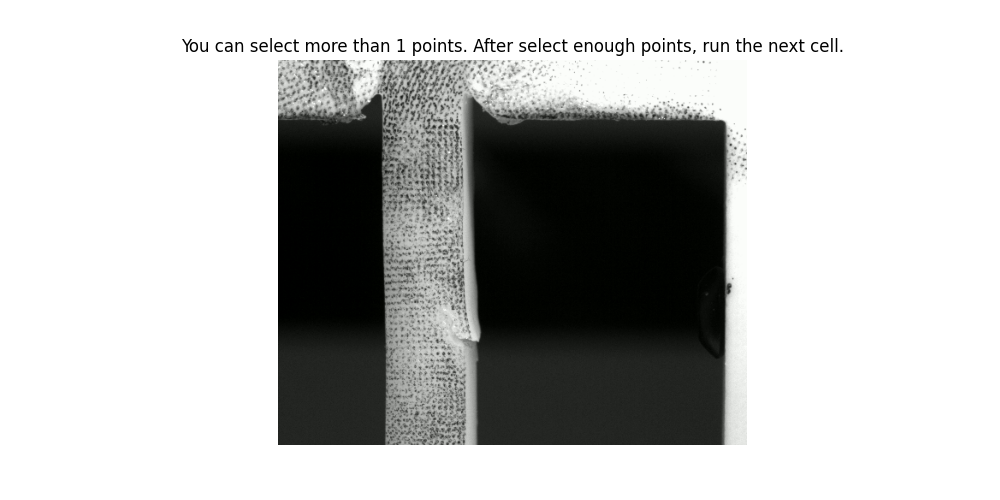

In [ ]:
# @title Select Any Points at Any Frame {form-width: "25%"}

select_frame = 0  # @param {type:"slider", min:0, max:49, step:1}

# Generate a colormap with 20 points, no need to change unless select more than 20 points
colormap = viz_utils.get_colors(20)

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(video[select_frame])
ax.axis('off')
ax.set_title(
    'You can select more than 1 points. After select enough points, run the'
    ' next cell.'
)

select_points = []


# Event handler for mouse clicks
def on_click(event):
  if event.button == 1 and event.inaxes == ax:  # Left mouse button clicked
    x, y = int(np.round(event.xdata)), int(np.round(event.ydata))

    select_points.append(np.array([x, y]))

    color = colormap[len(select_points) - 1]
    color = tuple(np.array(color) / 255.0)
    ax.plot(x, y, 'o', color=color, markersize=5)
    plt.draw()


fig.canvas.mpl_connect('button_press_event', on_click)
plt.show()

In [ ]:
## ------------------ clean the temporal data -------------------------
import gc
import sys
import traceback

# 清理上次推理的临时变量，保留 video、model 和 select_points
for name in ("frames", "query_points", "tracks", "visibles"):
    globals().pop(name, None)

# 报错记录也可能引用上次计算的中间变量
tb = getattr(sys, "last_traceback", None)
if tb is not None:
    traceback.clear_frames(tb)

gc.collect()
torch.cuda.empty_cache()

model.eval()
print("清理完成")

清理完成


In [ ]:
## ------------------ read the currect information of the video ----------------
print("视频总帧数：", len(video))
print("原视频高度、宽度：", video.shape[1:3])
print("推理高度、宽度：", resize_height, resize_width)
print("选点数量：", len(select_points))

视频总帧数： 1034
原视频高度、宽度： (450, 548)
推理高度、宽度： 256 256
选点数量： 6


In [ ]:
## --------------------------小样本检测-----------------------------
import gc
import sys
import traceback
import torch

# 清理上次失败的推理变量
for name in ("frames", "query_points", "tracks", "visibles", "outputs"):
    globals().pop(name, None)

tb = getattr(sys, "last_traceback", None)
if tb is not None:
    traceback.clear_frames(tb)

gc.collect()
torch.cuda.empty_cache()
model.eval()


class ChunkedExtraConvs(torch.nn.Module):
    def __init__(self, original, chunk_size=4):
        super().__init__()
        self._original_extra_convs = original
        self.chunk_size = chunk_size

    def forward(self, x):
        # x 的第一维是帧；所有帧都会被计算并按原顺序保留
        result = torch.empty_like(x)
        for start in range(0, x.shape[0], self.chunk_size):
            end = min(start + self.chunk_size, x.shape[0])
            result[start:end] = self._original_extra_convs(x[start:end])
        return result


# 支持重复运行，避免重复包裹
original_extra = getattr(
    model.extra_convs, "_original_extra_convs", model.extra_convs
)
assert original_extra is not None, "当前模型没有 extra_convs，请检查模型版本。"

chunked_extra = ChunkedExtraConvs(original_extra, chunk_size=2).eval()

# 小样本检查：一次计算 4 帧，与每批 2 帧计算进行比较
with torch.inference_mode():
    probe = torch.randn(4, 32, 32, model.lowres_dim, device=device)
    reference = original_extra(probe.clone())
    candidate = chunked_extra(probe.clone())

    torch.testing.assert_close(
        candidate, reference, rtol=1e-4, atol=1e-4
    )

del probe, reference, candidate

# 检查通过后，启用每批 4 帧的特征计算
chunked_extra.chunk_size = 4
model.extra_convs = chunked_extra
model.feature_extractor_chunk_size = 4
model.eval()

gc.collect()
torch.cuda.empty_cache()
print("小样本检查通过，已启用分批特征计算。")

小样本检查通过，已启用分批特征计算。


In [ ]:
# 推理的空间分辨率
resize_height = 256
resize_width = 256

assert len(select_points) > 0, "请先选择跟踪点。"
assert 0 <= select_frame < len(video), "选点帧号超出视频范围。"

height, width = video.shape[1:3]
points = np.asarray(select_points, dtype=np.float32)

# 选点格式：(帧号, y, x)，使用原始帧号
query_points = np.zeros((len(points), 3), dtype=np.float32)
query_points[:, 0] = int(select_frame)
query_points[:, 1] = points[:, 1]
query_points[:, 2] = points[:, 0]

query_points = transforms.convert_grid_coordinates(
    query_points,
    (1, height, width),
    (1, resize_height, resize_width),
    coordinate_format="tyx",
)

# 使用原始 video 的全部帧
frames_np = media.resize_video(
    video, (resize_height, resize_width)
)
frames = torch.tensor(frames_np, dtype=torch.float32, device=device)
frames.div_(255).mul_(2).sub_(1)
query_points = torch.tensor(query_points, device=device)
del frames_np

print(f"开始跟踪：{len(video)} 帧，{len(points)} 个点")

with torch.inference_mode():
    outputs = model(
        frames[None],
        query_points[None],
        query_chunk_size=1,  # 每次处理一个点，全部点都会计算
        refinement_resolutions=[(resize_height, resize_width)],
    )

    tracks = outputs["tracks"][0].cpu().numpy()

    visibles = (
        (1 - torch.sigmoid(outputs["occlusion"][0]))
        * (1 - torch.sigmoid(outputs["expected_dist"][0]))
        > 0.5
    ).cpu().numpy()

del outputs, frames, query_points
gc.collect()
torch.cuda.empty_cache()

# 转回原视频的像素坐标
tracks = transforms.convert_grid_coordinates(
    tracks,
    (resize_width, resize_height),
    (width, height),
)

assert tracks.shape == (len(points), len(video), 2)

# 恢复完整帧号、原始帧率，便于后续导出
frame_indices = np.arange(len(video))
tracking_fps = float(video_fps)

print("跟踪完成，轨迹数组形状：", tracks.shape)

video_viz = viz_utils.paint_point_track(
    video, tracks, visibles, colormap
)
media.show_video(video_viz, fps=tracking_fps)

**Plot time-disp**

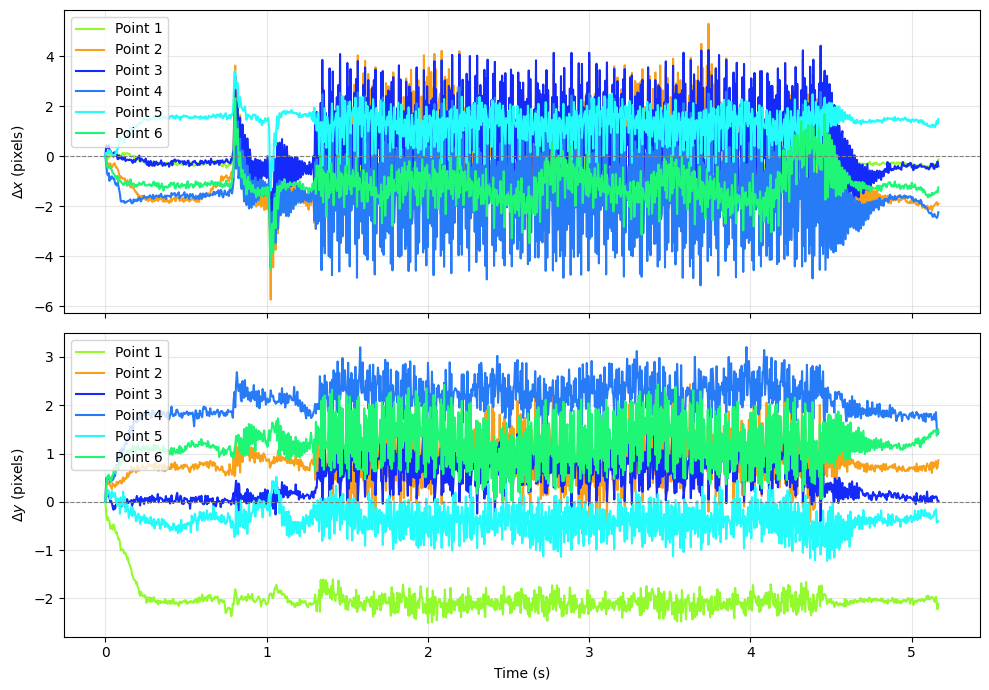

In [ ]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

reference_frame = 0  # 零位移参考帧，可修改
time_s = (
    np.arange(tracks.shape[1]) - reference_frame
) / float(video_fps)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

for p in range(tracks.shape[0]):
    # 相对于参考帧的位移
    dx = tracks[p, :, 0] - tracks[p, reference_frame, 0]
    dy = tracks[p, :, 1] - tracks[p, reference_frame, 1]

    # 不可靠的预测用断线表示
    valid = visibles[p].astype(bool)
    dx = np.where(valid, dx, np.nan)
    dy = np.where(valid, dy, np.nan)

    color = np.asarray(colormap[p]) / 255.0
    axes[0].plot(time_s, dx, color=color, label=f"Point {p+1}")
    axes[1].plot(time_s, dy, color=color, label=f"Point {p+1}")

axes[0].set_ylabel(r"$\Delta x$ (pixels)")
axes[1].set_ylabel(r"$\Delta y$ (pixels)")
axes[1].set_xlabel("Time (s)")

for ax in axes:
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display

n_points, n_frames, _ = tracks.shape

# 确认结果包含全部视频帧
assert n_frames == len(video), "轨迹帧数与原视频帧数不一致。"
assert visibles.shape == (n_points, n_frames)

fps = float(video_fps)  # 每秒帧数
assert np.isfinite(fps) and fps > 0, "请检查视频帧率。"

# 每行对应一帧
df_tracks = pd.DataFrame({
    "frame": np.arange(n_frames),
    "time_s": np.arange(n_frames) / fps,
})

# 添加每个点的 x、y 坐标及可见性标记
for p in range(n_points):
    df_tracks[f"p{p+1}_x_px"] = tracks[p, :, 0]
    df_tracks[f"p{p+1}_y_px"] = tracks[p, :, 1]
    df_tracks[f"p{p+1}_visible"] = visibles[p, :].astype(int)

# 查看前 10 行
display(df_tracks.head(5))

# 保存全部帧的数据
csv_path = "four_points_time_position.csv"
df_tracks.to_csv(csv_path, index=False, encoding="utf-8-sig")

print(f"已保存 {n_frames} 帧、{n_points} 个点的数据。")
print(f"时间范围：0 ～ {(n_frames - 1) / fps:.6f} 秒")

,frame,time_s,p1_x_px,p1_y_px,p1_visible,p2_x_px,p2_y_px,p2_visible,p3_x_px,p3_y_px,p3_visible,p4_x_px,p4_y_px,p4_visible
0,0,0.000000,59.879114,54.025227,1,221.015771,314.900898,1,207.953152,344.364337,1,183.815787,283.784977,1
1,1,0.005001,59.898635,53.783430,1,220.988617,315.282558,1,208.381816,344.491376,1,183.479571,284.277286,1
2,2,0.010001,59.736431,53.647412,1,220.674203,315.338928,1,208.307967,344.481972,1,183.147343,284.221299,1
3,3,0.015002,59.911220,53.711903,1,220.750728,315.263811,1,208.275401,344.532555,1,183.046913,284.256524,1
4,4,0.020002,59.819295,53.644674,1,220.658103,315.305313,1,208.395226,344.510416,1,183.139213,284.313770,1


已保存 1034 帧、4 个点的数据。
时间范围：0 ～ 5.165517 秒
